# Profile likelihood of the final structure

The profile likelihood shows, one parameter at a time, how the best achievable objective rises when the parameter is moved away from its estimate and *all the other free parameters are re-optimised*. It is the practical identifiability test that does not assume a quadratic objective:

$$ \text{PL}_j(\vartheta) \;=\; \min_{\theta_{-j}}\; \text{obj}(\theta)\Big|_{\theta_j = \vartheta}, \qquad
\text{the 95\% region is } \{\vartheta:\ \text{PL}_j(\vartheta) - \widehat{\text{obj}} \le \Delta_\text{LR}\},\quad \Delta_\text{LR} = \frac{\chi^2_{0.95,1}}{2N} = 0.0873 .$$

(parmest's objective is $\frac1N\sum_e\tfrac12\chi^2_e$, so a $\Delta\chi^2$ of 3.84 is $3.84/(2N)$ in the objective, $N = 22$.) A second threshold multiplies $\Delta_\text{LR}$ by the misfit scale $s^2 = 2N\,\text{obj}/(n_\text{outputs} - p)$, because the model misses the data by more than the measurement error.

**Implementation** (`uncertainty/profiles.py`). For every free parameter: 31 points, $\pm 0.5$ decades around the anchor (clipped to the theta bounds), two **continuation arms** from the anchor (each point is warm started at the previous point's theta and primal point), the other free parameters re-optimised with the tight monotone options (default and monotone options as retries). Classes per parameter: `identifiable` if both arms cross the threshold within the range, `one_sided` if one does, `flat` if none does. The crossings are linearly interpolated.

**Reading it.** Re-fits start without solver duals, so the profile points sit slightly above the best objective (about 0.03 in the saved run): crossings are only certain at about one third of the threshold. A `flat` profile of a parameter with a finite CV means the quadratic (Fisher) approximation is wrong for it.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from settings import RUN as RUN_SETTINGS, default_params
from uncertainty import profiles

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

FINAL = os.path.join(OUT, "final")
PROF = os.path.join(OUT, "profiles")
N_JOBS = int(os.environ.get("HK_N_JOBS", RUN_SETTINGS["n_jobs"]))

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : True (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. Run (`HK_RUN=1`)

`profiles.run_profiles(anchor_dir, out_dir, params)` reads `OUT/final/anchor_state.pkl` and `OUT/final/final_summary.json` (for the misfit scale $s^2$) and writes `profiles_all.csv` (one row per profile point: parameter, arm, offset, value, objective, status), `profile_summary.csv` and `profile_thresholds.json` into `OUT/profiles/`. There are $2\times 11$ arms of 16 points, distributed over the workers. The settings are the dict `params` below (defaults from `settings/uncertainty.csv` and `settings/thresholds.csv`); switch: `HK_N_JOBS`.

In [2]:
# Settings of the profile likelihood (defaults from settings/uncertainty.csv)
params = default_params("profiles")
params["profile_half_points"] = 15   # steps per arm (an arm has this + 1 points, the anchor included)
params["profile_span"] = 0.5         # half width of the profile in decades around the estimate
params["lr_alpha"] = 0.95            # level of the likelihood-ratio threshold
params["n_jobs"] = N_JOBS            # worker processes (HK_N_JOBS)
params

{'n_jobs': 8, 'lr_alpha': 0.95, 'profile_half_points': 15, 'profile_span': 0.5}

In [3]:
if RUN:
    profiles.run_profiles(FINAL, PROF, params)
else:
    print("RUN is False: the profiles are loaded from", PROF)

[     1s] check_bounds_contain_data: OK (balanced, cofactors, drains); Pi bounds (1.0, 20.0)


[     1s] 22 profile arms (11 params x 2), 16 points each


[    93s] arm K_g6p_1 +1 done (16 points, 0 failed)


[   117s] arm K_g6p_1 -1 done (16 points, 0 failed)


[   135s] arm Ks_g6p_pgi +1 done (16 points, 0 failed)


[   135s] arm Ks_g6p_pgi -1 done (16 points, 0 failed)


... (15 outputs left out)

[   260s] arm kcat_f_8 -1 done (16 points, 0 failed)


[   276s] arm kcat_f_9 +1 done (16 points, 0 failed)


[   298s] arm kcat_f_9 -1 done (16 points, 0 failed)


[   298s] profile summary (threshold 0.0873, scaled 0.2081):
            upper_decades_lr  lower_decades_lr      class_lr   class_lr_s2  max_dobj_up  max_dobj_down  min_dobj_anywhere  n_failed
param                                                                                                                              
K_g6p_1                  NaN               NaN          flat          flat       0.0360         0.0394             0.0258         0
Ks_g6p_pgi               NaN               NaN          flat          flat       0.0559         0.0332             0.0242         0
kcat_f_2                 NaN            0.1694     one_sided     one_sided       0.0342         0.2408             0.0235         0
kcat_f_3                 NaN            0.0543     one_sided     one_sided       0.0339        13.1185             0.0255         0
Ks_fbp_4              0.2329               NaN     one_sided          flat       0.2070         0.0352             0.0343         0
kcat_f_4       

In [4]:
# profiles computed but not summarised (an interrupted run): summarise what is saved
if (not os.path.exists(os.path.join(PROF, "profile_summary.csv"))) and os.path.exists(os.path.join(PROF, "profiles_all.csv")) and WRITABLE:
    profiles.summarize_saved(FINAL, PROF, params)

## 2. Summary

`obj_hat` is the lowest objective seen (the anchor or a profile point). For every parameter: the number of decades the profile can be moved up and down before the objective crosses the threshold (`NaN`: it never does inside the range), the class under both thresholds, and the largest increase of the objective inside the range.

In [5]:
prof_all = pd.read_csv(os.path.join(PROF, "profiles_all.csv")) if os.path.exists(os.path.join(PROF, "profiles_all.csv")) else None
summary = pd.read_csv(os.path.join(PROF, "profile_summary.csv"), index_col=0) if os.path.exists(os.path.join(PROF, "profile_summary.csv")) else None
thr = json.load(open(os.path.join(PROF, "profile_thresholds.json"))) if os.path.exists(os.path.join(PROF, "profile_thresholds.json")) else None

if thr is not None:
    print("thresholds: %.4f (LR 0.95), %.4f (misfit scaled, s2 = %.2f); obj_hat %.4f, anchor objective %.4f" % (
        thr["lr_threshold_0.95"], thr["lr_threshold_0.95_s2"], thr["s2"], thr["obj_hat"], thr["obj_anchor"]))

if summary is not None:
    print(summary["class_lr"].value_counts().to_dict())

summary

thresholds: 0.0873 (LR 0.95), 0.2081 (misfit scaled, s2 = 2.38); obj_hat 10.9137, anchor objective 10.9429
{'flat': 5, 'one_sided': 4, 'identifiable': 2}


,anchor,obj_hat,obj_anchor,n_failed,n_points,upper_decades_lr,lower_decades_lr,class_lr,upper_decades_lr_s2,lower_decades_lr_s2,class_lr_s2,max_dobj_up,max_dobj_down,min_dobj_anywhere
param,,,,,,,,,,,,,,
K_g6p_1,10.001076,10.913729,10.942883,0,27,NaN,NaN,flat,NaN,NaN,flat,0.035985,0.039403,0.025831
Ks_g6p_pgi,0.197194,10.913729,10.942883,0,32,NaN,NaN,flat,NaN,NaN,flat,0.055883,0.033247,0.024203
kcat_f_2,917.423639,10.913729,10.942883,0,19,NaN,0.169373,one_sided,NaN,0.437584,one_sided,0.034168,0.240818,0.023500
kcat_f_3,960.087926,10.913729,10.942883,0,18,NaN,0.054319,one_sided,NaN,0.095401,one_sided,0.033929,13.118521,0.025542
Ks_fbp_4,0.001002,10.913729,10.942883,0,18,0.232893,NaN,one_sided,NaN,NaN,flat,0.206984,0.035203,0.034256
kcat_f_4,2.699551,10.913729,10.942883,0,32,0.013885,0.016313,identifiable,0.038743,0.040084,identifiable,21.624903,18.535760,0.033573
kcat_f_5,5578.920937,10.913729,10.942883,0,25,NaN,NaN,flat,NaN,NaN,flat,0.034499,0.041169,0.028948
kcat_f_6,537.757240,10.913729,10.942883,0,26,NaN,NaN,flat,NaN,NaN,flat,0.062723,0.032557,0.000000
kcat_f_7,720.523954,10.913729,10.942883,0,22,NaN,NaN,flat,NaN,NaN,flat,0.035724,0.075917,0.027402


## 3. All profiles on one axis

Objective minus `obj_hat` (clipped to $[0, 0.5]$) against the offset of the parameter from its estimate in decades. A profile that rises above the dashed line on both sides is identifiable; on one side, one-sided; a profile that stays below the line over the whole range is flat.

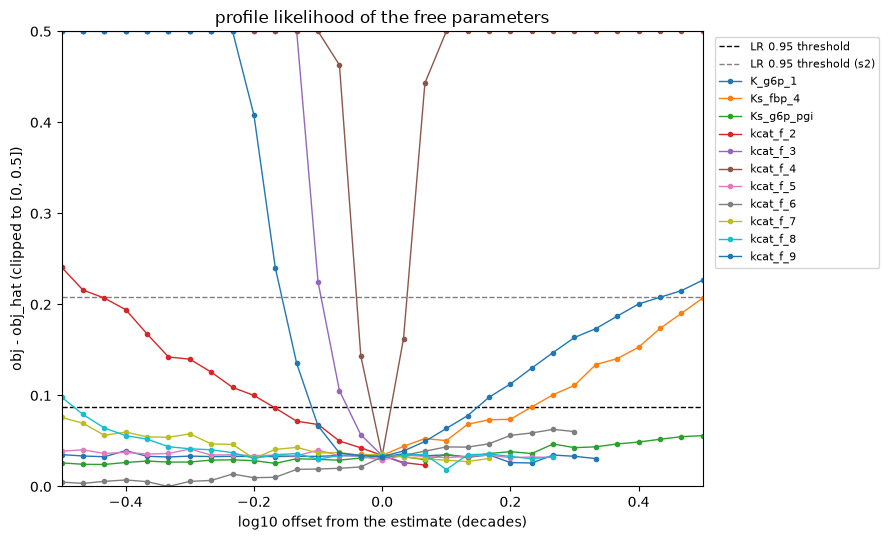

In [6]:
if prof_all is not None and thr is not None:
    prof = prof_all.dropna(subset=["obj"]).sort_values(["param", "log10_offset"])

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.axhline(thr["lr_threshold_0.95"], color="black", ls="--", lw=1, label="LR 0.95 threshold")
    ax.axhline(thr["lr_threshold_0.95_s2"], color="grey", ls="--", lw=1, label="LR 0.95 threshold (s2)")
    for param in prof["param"].unique():
        sub = prof[prof["param"] == param]
        ax.plot(sub["log10_offset"], np.clip(sub["obj"] - thr["obj_hat"], 0.0, 0.5), "o-", ms=3, lw=1, label=param)
    ax.set_xlim(-params["profile_span"], params["profile_span"])
    ax.set_ylim(0.0, 0.5)
    ax.set_xlabel("log10 offset from the estimate (decades)")
    ax.set_ylabel("obj - obj_hat (clipped to [0, 0.5])")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_title("profile likelihood of the free parameters")
    fig.tight_layout()
    plt.show()

## 4. Where each profile crosses the threshold

Bars: decades to the crossing on the lower and the upper side of the estimate (the axis limit, 0.5, means no crossing in the range). Tight identifiable parameters have short bars on both sides.

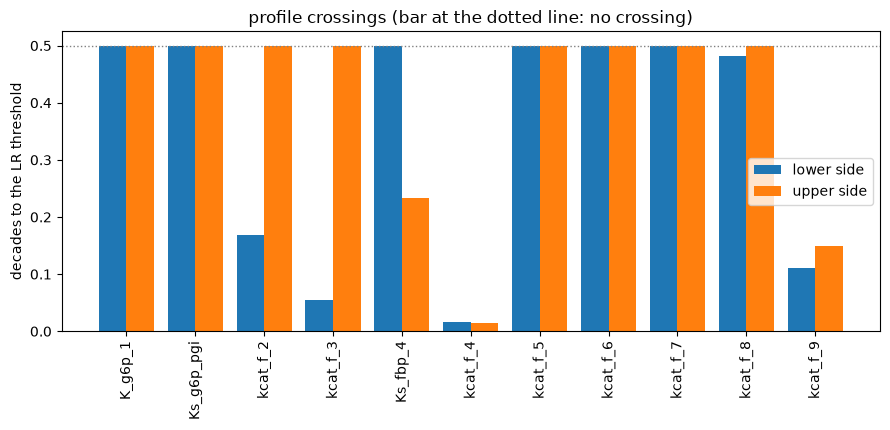

In [7]:
if summary is not None:
    fig, ax = plt.subplots(figsize=(9, 4.4))
    x = np.arange(len(summary))
    span = params["profile_span"]
    ax.bar(x - 0.2, summary["lower_decades_lr"].fillna(span), width=0.4, color="tab:blue", label="lower side")
    ax.bar(x + 0.2, summary["upper_decades_lr"].fillna(span), width=0.4, color="tab:orange", label="upper side")
    ax.axhline(span, color="grey", ls=":", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(summary.index, rotation=90)
    ax.set_ylabel("decades to the LR threshold")
    ax.legend()
    ax.set_title("profile crossings (bar at the dotted line: no crossing)")
    fig.tight_layout()
    plt.show()

### Status of the profile points

`status` of each point: `tight` (solved with the tight options), `default` / `monotone` (retries), `failed`, `at_bound_skipped` (the point would lie beyond a theta bound and repeats the previous one).

In [8]:
if prof_all is not None:
    display(prof_all.groupby(["param", "status"]).size().unstack(fill_value=0))

status,at_bound_skipped,tight
param,,
K_g6p_1,5,27
Ks_fbp_4,14,18
Ks_g6p_pgi,0,32
kcat_f_2,13,19
kcat_f_3,14,18
kcat_f_4,0,32
kcat_f_5,7,25
kcat_f_6,6,26
kcat_f_7,10,22
